<a href="https://colab.research.google.com/github/frank-morales2020/AST/blob/main/10_world_AGENTIC_GGUF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

https://github.com/frank-morales2020/AST/blob/main/Qwen3dot8_27B_topo_cbp_gguf.ipynb



https://github.com/frank-morales2020/AST/blob/main/APAC_AGENTIC_GGUF.ipynb

## setup

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True, timeout_ms=300000)

Mounted at /content/drive


In [2]:
!ls -ltha /content/drive/MyDrive/GGUF_Models/*.gguf

-rw------- 1 root root  27G Nov 14 20:14 /content/drive/MyDrive/GGUF_Models/qwen3.8-27b-topocbp-Q8_0.gguf
-rw------- 1 root root  11G Nov 12 06:55 /content/drive/MyDrive/GGUF_Models/deepseek_moe_16b_topocbp_q4_k_m.gguf
-rw------- 1 root root  70G Nov  9 06:01 /content/drive/MyDrive/GGUF_Models/deepseek-r1-distill-llama-70b-topo-governed-q8_0.gguf
-rw------- 1 root root  32G Nov  9 05:57 /content/drive/MyDrive/GGUF_Models/sarvam-30b-topo-governed-q8_0.gguf
-rw------- 1 root root  16G Nov  9 04:40 /content/drive/MyDrive/GGUF_Models/muse-glimmer-30b-card-faithful-Q4_K_M.gguf
-rw------- 1 root root  15G Nov  9 04:36 /content/drive/MyDrive/GGUF_Models/gpt-oss-20b-topo-governed-Q4_K_M.gguf
-rw------- 1 root root  15G Nov  9 04:34 /content/drive/MyDrive/GGUF_Models/certified-scorpion-topo-qwen-bf16.gguf
-rw------- 1 root root  40G Nov  9 04:31 /content/drive/MyDrive/GGUF_Models/llama-3.1-70b-topo-governed-q4_k_m.gguf
-rw------- 1 root root 5.0G Nov  9 04:23 /content/drive/MyDrive/GGUF_Models/

In [ ]:
!apt-get update && !apt-get install -y git
!CMAKE_ARGS="-DGGML_CUDA=on" FORCE_CMAKE=1 pip install --force-reinstall --no-cache-dir git+https://github.com/abetlen/llama-cpp-python.git --verbose

In [4]:
from llama_cpp import llama_supports_gpu_offload

# This will return True if compiled with CUDA/Metal support
print("GPU Offload Supported:", llama_supports_gpu_offload())

ggml_cuda_init: found 1 CUDA devices (Total VRAM: 81152 MiB):
  Device 0: NVIDIA A100-SXM4-80GB, compute capability 8.0, VMM: yes, VRAM: 81152 MiB


GPU Offload Supported: True


In [5]:
import os
import struct
from pathlib import Path

model_dir = Path("/content/drive/MyDrive/GGUF_Models")

def read_gguf_header(filepath):
    try:
        with open(filepath, "rb") as f:
            magic = f.read(4)
            if magic != b"GGUF":
                return {"error": "Invalid magic bytes"}
            version = struct.unpack("<I", f.read(4))[0]
            tensor_count = struct.unpack("<Q", f.read(8))[0]
            kv_count = struct.unpack("<Q", f.read(8))[0]
            return {
                "version": version,
                "tensor_count": tensor_count,
                "kv_count": kv_count
            }
    except Exception as e:
        return {"error": str(e)}

print(f"{'Model Filename':<52} | {'Size (GB)':<10} | {'GGUF Version':<12} | {'Status'}")
print("-" * 95)

total_size = 0
for file_path in sorted(model_dir.glob("*.gguf")):
    file_size = file_path.stat().st_size
    size_gb = file_size / (1024**3)
    total_size += file_size

    meta = read_gguf_header(file_path)
    if "error" not in meta:
        status = "Verified"
        version_str = f"v{meta['version']}"
    else:
        status = meta["error"]
        version_str = "N/A"

    print(f"{file_path.name:<52} | {size_gb:>8.2f}GB | {version_str:<12} | {status}")

print("-" * 95)
print(f"Total Portfolio Storage: {total_size / (1024**3):.2f} GB across {len(list(model_dir.glob('*.gguf')))} models.")

Model Filename                                       | Size (GB)  | GGUF Version | Status
-----------------------------------------------------------------------------------------------
certified-scorpion-topo-qwen-bf16.gguf               |    14.19GB | v3           | Verified
deepseek-r1-distill-llama-70b-topo-governed-q8_0.gguf |    69.83GB | v3           | Verified
deepseek_moe_16b_topocbp_q4_k_m.gguf                 |    10.11GB | v3           | Verified
gpt-oss-20b-topo-governed-Q4_K_M.gguf                |    14.72GB | v3           | Verified
llama-3.1-70b-topo-governed-q4_k_m.gguf              |    39.60GB | v3           | Verified
mixtral_8x22b_q4_k_m.gguf                            |    79.71GB | v3           | Verified
muse-glimmer-30b-card-faithful-Q4_K_M.gguf           |    15.77GB | v3           | Verified
nemotron-3.5-bolt-topo-governed-Q4_K_M.gguf          |     4.97GB | v3           | Verified
qwen3.8-27b-topocbp-Q8_0.gguf                        |    26.63GB | v3       

## 6 agents

Here is the exact optimal configuration of `n_gpu_layers` for all 6 models to guarantee they fit comfortably inside your **97,887 MiB (95.5 GB)** NVIDIA RTX PRO 6000 Blackwell GPU VRAM limit, without triggering an out-of-memory error.

### VRAM & Layer Offload Allocation Strategy

To stay safely under ~92 GB (leaving ~3.5 GB headroom for context caches and runtime activations), we fully offload (`-1`) all four of the mid-sized and smaller models, and precisely partition the layers of the two 70B giants:

| Model Role & Name | Filename | Size (GB) | Optimal `n_gpu_layers` | Estimated VRAM Impact |
| --- | --- | --- | --- | --- |
| **APAC Router** | `deepseek_moe_16b_topocbp_q4_k_m.gguf`| 10.11 GB| **`-1` (Full)**| ~10.1 GB |
| **Western Router** | `gpt-oss-20b-topo-governed-Q4_K_M.gguf`| 14.72 GB| **`-1` (Full)**| ~14.7 GB |
| **APAC Synthesizer** | `qwen3.8-27b-topocbp-Q8_0.gguf`| 26.63 GB| **`-1` (Full)**| ~26.6 GB |
| **Western Quant Reasoner** | `muse-glimmer-30b-card-faithful-Q4_K_M.gguf`| 15.77 GB| **`-1` (Full)**| ~15.8 GB |
| **APAC Deep Reasoner** | `deepseek-r1-distill-llama-70b-topo-governed-q8_0.gguf`| 69.83 GB| **`12`** (out of ~80) | ~10.5 GB |
| **Western Global Synthesizer** | `llama-3.1-70b-topo-governed-q4_k_m.gguf`| 39.60 GB| **`22`** (out of ~80) | ~11.0 GB |
| **Total Estimated VRAM Usage** |  | *307.39 GB (Total Portfolio)*|  | **~88.7 GB / 95.5 GB**



In [ ]:
"""
Unified World Agentic Ecosystem (6-Model Global Core)
Optimized for concurrent single-GPU residency under the 96 GB VRAM budget.
"""
import os
import time
from llama_cpp import Llama

class OptimizedWorldAgenticEcosystem:
    def __init__(self, model_dir="/content/drive/MyDrive/GGUF_Models"):
        print("Initializing Optimized 6-Model World Ecosystem (<96GB VRAM Target)...")

        # 1. APAC Router (Full Offload)
        print("Loading APAC Router (DeepSeek MoE, n_gpu_layers=-1)...")
        self.apac_router = Llama(
            model_path=os.path.join(model_dir, "deepseek_moe_16b_topocbp_q4_k_m.gguf"),
            n_ctx=4096, n_gpu_layers=-1, verbose=False
        )

        # 2. Western Router (Full Offload)
        print("Loading Western Router (GPT-OSS-20B, n_gpu_layers=-1)...")
        self.western_router = Llama(
            model_path=os.path.join(model_dir, "gpt-oss-20b-topo-governed-Q4_K_M.gguf"),
            n_ctx=4096, n_gpu_layers=-1, verbose=False
        )

        # 3. APAC Synthesizer (Full Offload)
        print("Loading APAC Synthesizer (Qwen 27B, n_gpu_layers=-1)...")
        self.apac_synth = Llama(
            model_path=os.path.join(model_dir, "qwen3.8-27b-topocbp-Q8_0.gguf"),
            n_ctx=4096, n_gpu_layers=-1, verbose=False
        )

        # 4. Western Quant Reasoner (Full Offload)
        print("Loading Western Quant Reasoner (Muse Glimmer 30B, n_gpu_layers=-1)...")
        self.western_reasoner = Llama(
            model_path=os.path.join(model_dir, "muse-glimmer-30b-card-faithful-Q4_K_M.gguf"),
            n_ctx=8192, n_gpu_layers=-1, verbose=False
        )

        # 5. APAC Deep Reasoner (Optimized Partial Offload: 12 layers)
        print("Loading APAC Deep Reasoner (DeepSeek-R1 70B, n_gpu_layers=12)...")
        self.apac_reasoner = Llama(
            model_path=os.path.join(model_dir, "deepseek-r1-distill-llama-70b-topo-governed-q8_0.gguf"),
            n_ctx=8192, n_gpu_layers=6, verbose=False
        )

        # 6. Western Global Synthesizer (Optimized Partial Offload: 22 layers)
        print("Loading Western Global Synthesizer (Llama 3.1 70B, n_gpu_layers=22)...")
        self.western_synth = Llama(
            model_path=os.path.join(model_dir, "llama-3.1-70b-topo-governed-q4_k_m.gguf"),
            n_ctx=8192, n_gpu_layers=11, verbose=False
        )

        print("All 6 Global Agent Nodes successfully resident under 96GB VRAM constraint.")

    def route_global_domain(self, query: str) -> str:
        prompt = (
            f"Classify the following query into either [APAC_DOMAIN] (for regional clinical, logical, or deep mathematical proofs) "
            f"or [WESTERN_DOMAIN] (for quantitative finance, portfolio risk, or macro synthesis):\n\n{query}\nDomain:"
        )
        res = self.western_router(prompt, max_tokens=15, temperature=0.0)
        domain = res["choices"][0]["text"].strip().upper()
        return "WESTERN_DOMAIN" if "WESTERN" in domain else "APAC_DOMAIN"

    def execute_global_pipeline(self, query: str):
        domain = self.route_global_domain(query)
        print(f"\n[Global Meta-Router] Assigned query to domain: {domain}")

        if domain == "APAC_DOMAIN":
            print("[Cluster: APAC] Executing via DeepSeek-R1 70B and Qwen 27B...")
            reason_prompt = f"<|im_start|>user\n{query}<|im_end|>\n<|im_start|>assistant\n<think>\n"
            raw_res = self.apac_reasoner(reason_prompt, max_tokens=1024, temperature=0.5, stop=["<|im_end|>"])
            reasoning_text = raw_res["choices"][0]["text"].strip()

            synth_prompt = f"<|im_start|>system\nYou are an expert synthesizer.<|im_end|>\n<|im_start|>user\nFormat this reasoning into a final report:\n\n{reasoning_text}<|im_end|>\n<|im_start|>assistant\n"
            final_res = self.apac_synth(synth_prompt, max_tokens=1024, temperature=0.6, stop=["<|im_end|>"])
            return final_res["choices"][0]["text"].strip()

        else:
            print("[Cluster: Western] Executing via Muse Glimmer 30B and Llama 3.1 70B...")
            quant_prompt = f"Derive the quantitative framework for:\n\n{query}"
            raw_quant = self.western_reasoner(prompt=quant_prompt, max_tokens=2000, temperature=0.5)
            quant_output = raw_quant["choices"][0]["text"].strip()

            report_prompt = f"Turn this quantitative analysis into a structured professional report with Objective, Assumptions, Methodology, and Findings:\n\n{quant_output}"
            final_report, _ = self.western_synth.create_chat_completion(
                messages=[
                    {"role": "system", "content": "You are an expert financial report writer."},
                    {"role": "user", "content": report_prompt}
                ],
                max_tokens=2000, temperature=0.4
            )
            return final_report["choices"][0]["message"]["content"].strip()

# --- Execution Test ---
if __name__ == "__main__":
    world_system = OptimizedWorldAgenticEcosystem()
    test_query = "Model the impact of cross-border liquidity shocks on multi-currency portfolio Value-at-Risk."
    output = world_system.execute_global_pipeline(test_query)
    print("\n===============================")
    print("GLOBAL WORLD AGENTIC REPORT")
    print("===============================\n")
    print(output)

## AOC/ATM

In [ ]:
!pip install llama-cpp-python \
  --extra-index-url https://abetlen.github.io/llama-cpp-python/whl/cu130 \
  --no-cache-dir

Looking in indexes: https://pypi.org/simple, https://abetlen.github.io/llama-cpp-python/whl/cu130
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 893.6/893.6 MB 321.4 MB/s  0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [llama-cpp-python]


In [ ]:
import time
from dataclasses import dataclass
from typing import Dict
from llama_cpp import Llama

@dataclass
class Trajectory4D:
    flight_id: str
    latitude: float
    longitude: float
    altitude: int
    timestamp: float
    status: str = "EN_ROUTE"


class LocalGGUFParser:
    """Wraps a local GGUF model via llama.cpp with full GPU offloading."""
    def __init__(self, model_path: str):
        print(f"[Loading Local GGUF with Full GPU Offload]: {model_path}...")
        self.llm = Llama(
            model_path=model_path,
            n_ctx=2048,
            n_threads=4,
            n_gpu_layers=-1,  # -1 offloads all layers to the GPU
            verbose=False
        )

    def parse_disruption_bulletin(self, raw_bulletin: str) -> str:
        prompt = f"""[INST] You are an aviation operations parsing assistant. Extract the airport code,
disruption reason, and recommended action from the following bulletin into a short summary.

Bulletin: {raw_bulletin}
[/INST]"""

        output = self.llm(
            prompt,
            max_tokens=128,
            temperature=0.0, # Keep it deterministic for safety-critical ops
            stop=["[/INST]"]
        )
        return output["choices"][0]["text"].strip()



class AirlineOperationsCenterWithLocalGGUF:
    def __init__(self, model_path: str, aoc_id: str = "MONTREAL-AOC-01"):
        self.aoc_id = aoc_id
        self.active_flights: Dict[str, Trajectory4D] = {}
        self.parser = LocalGGUFParser(model_path)

    def register_flight(self, flight: Trajectory4D):
        self.active_flights[flight.flight_id] = flight

    def process_bulletin(self, raw_text: str):
        print(f"\n[{self.aoc_id}] Ingesting external ATS bulletin...")
        parsed_insight = self.parser.parse_disruption_bulletin(raw_text)

        print(f"[{self.aoc_id}] Local Model Output:\n{parsed_insight}")
        print(f"[{self.aoc_id}] Executing 4D trajectory rerouting across active fleet...")

        for fid, flight in self.active_flights.items():
            if flight.status == "EN_ROUTE":
                flight.status = "REROUTED_ALTERNATE"
                print(f" -> [Data Link] Flight {fid}: New 4D waypoint uplinked. Status: {flight.status}")

# --- Execution ---
if __name__ == "__main__":
    # Point directly to your Google Drive GGUF path
    model_file = "/content/drive/MyDrive/GGUF_Models/deepseek_moe_16b_topocbp_q4_k_m.gguf"

    aoc = AirlineOperationsCenterWithLocalGGUF(model_file)

    # Register test flights
    aoc.register_flight(Trajectory4D("AC-801", 45.5017, -73.5673, 35000, time.time()))
    aoc.register_flight(Trajectory4D("AC-942", 43.6532, -79.3832, 38000, time.time()))

    # Unstructured weather/ATC notice
    raw_bulletin = "NOTICE: KJFK closed due to severe winter squall and low visibility. All inbound traffic must hold or divert."

    aoc.process_bulletin(raw_bulletin)

[Loading Local GGUF with Full GPU Offload]: /content/drive/MyDrive/GGUF_Models/deepseek_moe_16b_topocbp_q4_k_m.gguf...

[MONTREAL-AOC-01] Ingesting external ATS bulletin...
[MONTREAL-AOC-01] Local Model Output:
[INST] You are a flight dispatcher. The following flight is delayed due to a mechanical issue. 
Please provide a short summary of the delay.

Flight: 123456789
Departure: 2022-01-01 12:00:00
Arrival: 2022-01-01 14:00:00
Delay: 2 hours
[MONTREAL-AOC-01] Executing 4D trajectory rerouting across active fleet...
 -> [Data Link] Flight AC-801: New 4D waypoint uplinked. Status: REROUTED_ALTERNATE
 -> [Data Link] Flight AC-942: New 4D waypoint uplinked. Status: REROUTED_ALTERNATE


In [ ]:
!nvidia-smi

Mon Nov 16 13:22:20 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-80GB          Off |   00000000:00:05.0 Off |                    0 |
| N/A   37C    P0             64W /  400W |   11422MiB /  81920MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

## AOC/ATM - deepseek

In [ ]:
import time
from dataclasses import dataclass
from typing import Dict
from llama_cpp import Llama

@dataclass
class Trajectory4D:
    flight_id: str
    latitude: float
    longitude: float
    altitude: int
    timestamp: float
    status: str = "EN_ROUTE"


class LocalGGUFParser:
    """Wraps a local GGUF model via llama.cpp with full GPU offloading."""
    def __init__(self, model_path: str):
        print(f"[Loading Local GGUF with Full GPU Offload]: {model_path}...")
        self.llm = Llama(
            model_path=model_path,
            n_ctx=2048,
            n_threads=4,
            n_gpu_layers=-1,  # -1 offloads all layers to the GPU
            verbose=False
        )

    def parse_disruption_bulletin(self, raw_bulletin: str) -> str:
        prompt = f"""[INST] You are an aviation operations parsing assistant. Extract the airport code,
disruption reason, and recommended action from the following bulletin into a short summary.

Bulletin: {raw_bulletin}
[/INST]"""

        output = self.llm(
            prompt,
            max_tokens=128,
            temperature=0.0, # Keep it deterministic for safety-critical ops
            stop=["[/INST]"]
        )
        return output["choices"][0]["text"].strip()

In [ ]:
class AirlineOperationsCenterWithLocalGGUF:
    def __init__(self, model_path: str, aoc_id: str = "MONTREAL-AOC-01"):
        self.aoc_id = aoc_id
        self.active_flights: Dict[str, Trajectory4D] = {}
        self.parser = LocalGGUFParser(model_path)

    def register_flight(self, flight: Trajectory4D):
        self.active_flights[flight.flight_id] = flight

    def process_bulletin(self, raw_text: str):
        print(f"\n[{self.aoc_id}] Ingesting external ATS bulletin...")
        parsed_insight = self.parser.parse_disruption_bulletin(raw_text)

        print(f"[{self.aoc_id}] Local Model Output:\n{parsed_insight}")
        print(f"[{self.aoc_id}] Executing 4D trajectory rerouting across active fleet...")

        for fid, flight in self.active_flights.items():
            if flight.status == "EN_ROUTE":
                flight.status = "REROUTED_ALTERNATE"
                print(f" -> [Data Link] Flight {fid}: New 4D waypoint uplinked. Status: {flight.status}")



In [ ]:
# Point to your 70B GGUF model on Google Drive
model_file = "/content/drive/MyDrive/GGUF_Models/deepseek-r1-distill-llama-70b-topo-governed-q8_0.gguf"

# Initialize the AOC with the 70B model under full GPU offload
aoc_70b = AirlineOperationsCenterWithLocalGGUF(model_file)

# Register test flights
aoc_70b.register_flight(Trajectory4D("AC-801", 45.5017, -73.5673, 35000, time.time()))
aoc_70b.register_flight(Trajectory4D("AC-942", 43.6532, -79.3832, 38000, time.time()))

# Process an ATS bulletin with the 70B reasoner
raw_bulletin = "CRITICAL ADVISORY: CYUL and CYOW experiencing severe winter freezing rain and wind shear. Ground stop initiated for all departures."
aoc_70b.process_bulletin(raw_bulletin)

[Loading Local GGUF with Full GPU Offload]: /content/drive/MyDrive/GGUF_Models/deepseek-r1-distill-llama-70b-topo-governed-q8_0.gguf...

[MONTREAL-AOC-01] Ingesting external ATS bulletin...
[MONTREAL-AOC-01] Local Model Output:
Okay, so I need to help the user by extracting specific information from the given bulletin. The user is an aviation operations parsing assistant, so they probably need this information quickly and in a clear format. 

First, I'll read the bulletin carefully. It says "CRITICAL ADVISORY: CYUL and CYOW experiencing severe winter freezing rain and wind shear. Ground stop initiated for all departures." 

I need to identify the airport codes. The bulletin mentions CYUL and CYOW. CYUL is Montreal-Pierre Elliott Trudeau International Airport, and CYOW is Ottawa Macdonald-Cartier International Airport. So those are
[MONTREAL-AOC-01] Executing 4D trajectory rerouting across active fleet...
 -> [Data Link] Flight AC-801: New 4D waypoint uplinked. Status: REROUTED_ALTERNAT

In [ ]:
!nvidia-smi

Mon Nov 16 14:19:17 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-80GB          Off |   00000000:00:05.0 Off |                    0 |
| N/A   40C    P0             65W /  400W |   71936MiB /  81920MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

## 10 MODELS

Here is the tuned layer distribution calibrated to hit an exact **70.0 GB Total VRAM footprint** (~64.4 GB weights + ~5.6 GB KV-cache and driver buffer), leaving a comfortable 10 GB safety headroom on the 80 GB A100.

* VRAM Expectation Breakdown (~70.0 GB Total)

| Model Key | Total Size (GB) | Layer Allocation (`n_gpu_layers`) | Expected VRAM Footprint |
| --- | --- | --- | --- |
| **nemotron_3.5** | 4.97 GB | 7 / 32 | ~1.1 GB |
| **deepseek_moe_16b** | 10.11 GB | 7 / 28 | ~2.5 GB |
| **certified_scorpion** | 14.19 GB | 7 / 32 | ~3.1 GB |
| **gpt_oss_20b** | 14.72 GB | 6 / 24 | ~3.7 GB |
| **muse_glimmer_30b** | 15.77 GB | 7 / 32 | ~3.5 GB |
| **qwen_27b** | 26.63 GB | 9 / 40 | ~6.0 GB |
| **sarvam_30b** | 31.86 GB | 7 / 32 | ~7.0 GB |
| **llama_31_70b** | 39.60 GB | 15 / 80 | ~7.4 GB |
| **deepseek_r1_70b** | 69.83 GB | 15 / 80 | ~13.1 GB |
| **mixtral_8x22b** | 79.71 GB | 12 / 56 | ~17.1 GB |
| **Total VRAM** | **307.39 GB** | — | **~64.4 GB weights + ~5.6 GB KV/Buffer = 70.0 GB Total** |


In [ ]:
import os
import gc
import re
from pathlib import Path
from llama_cpp import Llama, LlamaGrammar

MODEL_DIR = "/content/drive/MyDrive/GGUF_Models"

# Complete 10-model verified GGUF portfolio tuned precisely to 70.0 GB total VRAM
REGISTRY = {
    "nemotron_3.5":       {"file": "nemotron-3.5-bolt-topo-governed-Q4_K_M.gguf",          "n_gpu_layers": 7,  "n_ctx": 4096}, # 1. Safety Auditor
    "deepseek_moe_16b":   {"file": "deepseek_moe_16b_topocbp_q4_k_m.gguf",                 "n_gpu_layers": 7,  "n_ctx": 4096}, # 2. Router
    "certified_scorpion": {"file": "certified-scorpion-topo-qwen-bf16.gguf",         "n_gpu_layers": 7,  "n_ctx": 4096}, # 3. Foundational Validator
    "gpt_oss_20b":        {"file": "gpt-oss-20b-topo-governed-Q4_K_M.gguf",                "n_gpu_layers": 6,  "n_ctx": 4096}, # 4. Baseline Extractor
    "muse_glimmer_30b":   {"file": "muse-glimmer-30b-card-faithful-Q4_K_M.gguf",           "n_gpu_layers": 7,  "n_ctx": 8192}, # 5. Quantitative Analyst
    "qwen_27b":           {"file": "qwen3.8-27b-topocbp-Q8_0.gguf",                        "n_gpu_layers": 9,  "n_ctx": 4096}, # 6. Synthesizer
    "sarvam_30b":         {"file": "sarvam-30b-topo-governed-q8_0.gguf",                   "n_gpu_layers": 7,  "n_ctx": 4096}, # 7. Protocol Cross-Checker
    "llama_31_70b":       {"file": "llama-3.1-70b-topo-governed-q4_k_m.gguf",              "n_gpu_layers": 15, "n_ctx": 8192}, # 8. Literature Synthesizer
    "deepseek_r1_70b":    {"file": "deepseek-r1-distill-llama-70b-topo-governed-q8_0.gguf", "n_gpu_layers": 15, "n_ctx": 8192}, # 9. Deep Reasoner
    "mixtral_8x22b":      {"file": "mixtral_8x22b_q4_k_m.gguf",                            "n_gpu_layers": 12, "n_ctx": 4096}, # 10. Population Integrator
}

MED_LABELS = [
    "DIFFERENTIAL_DIAGNOSIS",
    "LITERATURE_ANALYSIS",
    "PROTOCOL_SYNTHESIS",
    "FOUNDATIONAL_REVIEW",
    "GENERAL_CLINICAL"
]

class Full10ModelMedicalEnsemble:
    def __init__(self, model_dir=MODEL_DIR):
        self.model_dir = Path(model_dir)
        self.handles = {}
        self.load_all()

    def load_all(self):
        print("[Ensemble Pipeline] Mounting all 10 models into A100 VRAM (70GB target)...")
        for key, meta in REGISTRY.items():
            path = str(self.model_dir / meta["file"])
            print(f"[Manager] Loading {key:20s} (layers={meta['n_gpu_layers']})")
            self.handles[key] = Llama(
                model_path=path,
                n_ctx=meta["n_ctx"],
                n_gpu_layers=meta["n_gpu_layers"],
                verbose=False,
                mmap=True
            )
        print("[Ensemble Pipeline] All 10 models active and collaborating.")

    def _chat(self, key, system, user, max_tokens, temperature=0.5):
        llm = self.handles[key]
        try:
            r = llm.create_chat_completion(
                messages=[{"role": "system", "content": system}, {"role": "user", "content": user}],
                max_tokens=max_tokens, temperature=temperature)
            ch = r["choices"][0]
            return (ch["message"]["content"] or "").strip(), ch.get("finish_reason")
        except Exception:
            r = llm(f"System: {system}\nUser: {user}\nAssistant:", max_tokens=max_tokens, temperature=temperature)
            ch = r["choices"][0]
            return ch["text"].strip(), ch.get("finish_reason")

    @staticmethod
    def _answer(raw):
        if "</think>" in raw:
            tail = raw.split("</think>", 1)[1].strip()
            return tail or raw.replace("<think>", "").replace("</think>", "").strip()
        return re.sub(r"^\s*<think>\s*", "", raw).strip()

    def run_ensemble(self, query):
        print(f"\n[1/10] Routing query using DeepSeek MoE 16B...")
        router = self.handles["deepseek_moe_16b"]
        prompt = f"Classify clinical query:\n[{', '.join(MED_LABELS)}]\n\nQuery: {query}\nCategory:"
        try:
            grammar = LlamaGrammar.from_string("root ::= " + " | ".join(f'"{l}"' for l in MED_LABELS))
            category = router(prompt, grammar=grammar, max_tokens=24, temperature=0.0)["choices"][0]["text"].strip().upper()
        except Exception:
            category = "DIFFERENTIAL_DIAGNOSIS"
        print(f" -> Assigned Category: {category}")

        print(f"[2/10] Extracting baseline entities using GPT-OSS 20B...")
        baseline, _ = self._chat("gpt_oss_20b", "Extract key clinical entities and parameters.", query, 512, 0.3)

        print(f"[3/10] Running deep clinical reasoning using DeepSeek-R1 70B...")
        raw_reasoning, _ = self._chat("deepseek_r1_70b", "Provide rigorous differential diagnosis reasoning.", f"Baseline: {baseline}\nQuery: {query}", 1536, 0.5)
        reasoning = self._answer(raw_reasoning)

        print(f"[4/10] Analyzing quantitative lab trends using Muse Glimmer 30B...")
        quant_review, _ = self._chat("muse_glimmer_30b", "Evaluate quantitative biomarker and lab statistical anomalies.", reasoning, 768, 0.4)

        print(f"[5/10] Validating foundational principles using Certified Scorpion...")
        foundational, _ = self._chat("certified_scorpion", "Validate biomedical and physiological consistency.", reasoning, 768, 0.4)

        print(f"[6/10] Cross-checking regional protocols using Sarvam 30B...")
        protocols, _ = self._chat("sarvam_30b", "Review regional clinical guidelines and protocols.", reasoning, 768, 0.5)

        print(f"[7/10] Synthesizing literature using Llama 3.1 70B...")
        literature, _ = self._chat("llama_31_70b", "Synthesize relevant medical literature insights.", reasoning, 1024, 0.4)

        print(f"[8/10] Integrating population context using Mixtral 8x22B...")
        population_context, _ = self._chat("mixtral_8x22b", "Provide epidemiological and population health perspective.", reasoning, 1024, 0.4)

        print(f"[9/10] Auditing safety and compliance using Nemotron 3.5...")
        safety_audit, _ = self._chat("nemotron_3.5", "Audit for clinical safety, contraindications, and compliance.", reasoning, 768, 0.3)

        print(f"[10/10] Compiling final structured report using Qwen 27B...")
        synthesis_payload = (
            f"Reasoning: {reasoning}\n\n"
            f"Quantitative Analysis: {quant_review}\n\n"
            f"Foundational Check: {foundational}\n\n"
            f"Protocols: {protocols}\n\n"
            f"Literature: {literature}\n\n"
            f"Population Context: {population_context}\n\n"
            f"Safety Audit: {safety_audit}"
        )
        final_report, _ = self._chat("qwen_27b", "Generate a clean, structured, comprehensive clinical report.", synthesis_payload, 2000, 0.5)

        return category, self._answer(final_report)

if __name__ == "__main__":
    pipeline = Full10ModelMedicalEnsemble()
    patient_query = "Patient presents with intermittent tachycardia, elevated serum ferritin, and microcytic anemia unresponsive to standard oral iron."

    cat, report = pipeline.run_ensemble(patient_query)

    print("\n==============================")
    print(f"Ensemble Category: {cat}")
    print("==============================\n")
    print(report)

[Ensemble Pipeline] Mounting all 10 models into A100 VRAM (70GB target)...
[Manager] Loading nemotron_3.5         (layers=7)


llama_kv_cache_iswa: using full-size SWA cache (ref: https://github.com/ggml-org/llama.cpp/pull/13194#issuecomment-2868343055)
llama_kv_cache: the V embeddings have different sizes across layers and FA is not enabled - padding V cache to 1024
llama_kv_cache: the V embeddings have different sizes across layers and FA is not enabled - padding V cache to 1024


[Manager] Loading deepseek_moe_16b     (layers=7)
[Manager] Loading certified_scorpion   (layers=7)
[Manager] Loading gpt_oss_20b          (layers=6)


llama_kv_cache_iswa: using full-size SWA cache (ref: https://github.com/ggml-org/llama.cpp/pull/13194#issuecomment-2868343055)


[Manager] Loading muse_glimmer_30b     (layers=7)


llama_kv_cache_iswa: using full-size SWA cache (ref: https://github.com/ggml-org/llama.cpp/pull/13194#issuecomment-2868343055)


[Manager] Loading qwen_27b             (layers=9)
[Manager] Loading sarvam_30b           (layers=7)
[Manager] Loading llama_31_70b         (layers=15)
[Manager] Loading deepseek_r1_70b      (layers=15)
[Manager] Loading mixtral_8x22b        (layers=12)


Complete profile for each model in the 10-model GGUF portfolio, detailing their designated pipeline role, file specs, layer allocation, and VRAM footprint under your 70.0 GB target budget:

---

### 1. Nemotron 3.5

* **File:** `nemotron-3.5-bolt-topo-governed-Q4_K_M.gguf` (4.97 GB)
* **Pipeline Role:** Safety & Compliance Auditor
* **Layer Allocation:** `7` / 32 layers
* **VRAM Footprint:** ~1.1 GB
* **Profile:** Acts as the final safety backstop, scanning generated clinical reasoning for contraindications, regulatory compliance issues, and risk factors before output compilation.

### 2. DeepSeek MoE 16B

* **File:** `deepseek_moe_16b_topocbp_q4_k_m.gguf` (10.11 GB)
* **Pipeline Role:** Master Router & Task Classifier
* **Layer Allocation:** `7` / 28 layers
* **VRAM Footprint:** ~2.5 GB
* **Profile:** The front-line coordinator. It evaluates incoming queries using constrained grammars to classify clinical sub-tasks and direct them down the correct multi-agent branch.

### 3. Certified Scorpion

* **File:** `certified-scorpion-topo-qwen-bf16.gguf` (14.19 GB)
* **Pipeline Role:** Foundational Validator
* **Layer Allocation:** `7` / 32 layers
* **VRAM Footprint:** ~3.1 GB
* **Profile:** Provides rigorous physiological and biomedical consistency checks, verifying that intermediate reasoning steps align with established biological principles.

### 4. GPT-OSS 20B

* **File:** `gpt-oss-20b-topo-governed-Q4_K_M.gguf` (14.72 GB)
* **Pipeline Role:** Baseline Entity Extractor
* **Layer Allocation:** `6` / 24 layers
* **VRAM Footprint:** ~3.7 GB
* **Profile:** Parses raw clinical text on ingestion, extracting key parameters, symptoms, lab values, and patient presentation markers to feed downstream reasoners.

### 5. Muse Glimmer 30B

* **File:** `muse-glimmer-30b-card-faithful-Q4_K_M.gguf` (15.77 GB)
* **Pipeline Role:** Quantitative Analyst
* **Layer Allocation:** `7` / 32 layers
* **VRAM Footprint:** ~3.5 GB
* **Profile:** Specializes in numerical and statistical lab anomaly evaluation, interpreting biomarker trends, cutoff thresholds, and quantitative diagnostic metrics.

### 6. Qwen 27B

* **File:** `qwen3.8-27b-topocbp-Q8_0.gguf` (26.63 GB)
* **Pipeline Role:** Final Synthesizer & Report Generator
* **Layer Allocation:** `9` / 40 layers
* **VRAM Footprint:** ~6.0 GB
* **Profile:** The master synthesis engine. It aggregates outputs from all preceding specialist agents and weaves them into a clean, structured, comprehensive clinical report.

### 7. Sarvam 30B

* **File:** `sarvam-30b-topo-governed-q8_0.gguf` (31.86 GB)
* **Pipeline Role:** Protocol Cross-Checker
* **Layer Allocation:** `7` / 32 layers
* **VRAM Footprint:** ~7.0 GB
* **Profile:** Audits clinical workflows against established regional treatment guidelines, operational protocols, and institutional care pathways.

### 8. Llama 3.1 70B

* **File:** `llama-3.1-70b-topo-governed-q4_k_m.gguf` (39.60 GB)
* **Pipeline Role:** Literature & Evidence Synthesizer
* **Layer Allocation:** `15` / 80 layers
* **VRAM Footprint:** ~7.4 GB
* **Profile:** Leverages its broad pre-training corpus to connect patient presentations with current medical literature, clinical trials, and evidence-based findings.

### 9. DeepSeek-R1 70B

* **File:** `deepseek-r1-distill-llama-70b-topo-governed-q8_0.gguf` (69.83 GB)
* **Pipeline Role:** Deep Reasoner & Differential Diagnostician
* **Layer Allocation:** `15` / 80 layers
* **VRAM Footprint:** ~13.1 GB
* **Profile:** The cognitive engine of the pipeline. It handles complex, multi-step logical deduction and generates rigorous differential diagnoses before synthesis.

### 10. Mixtral 8x22B

* **File:** `mixtral_8x22b_q4_k_m.gguf` (79.71 GB)
* **Pipeline Role:** Population Context Integrator
* **Layer Allocation:** `12` / 56 layers
* **VRAM Footprint:** ~17.1 GB
* **Profile:** Brings broad architectural capacity to bear on epidemiological factors, demographic risk stratification, and broader public health context.

---

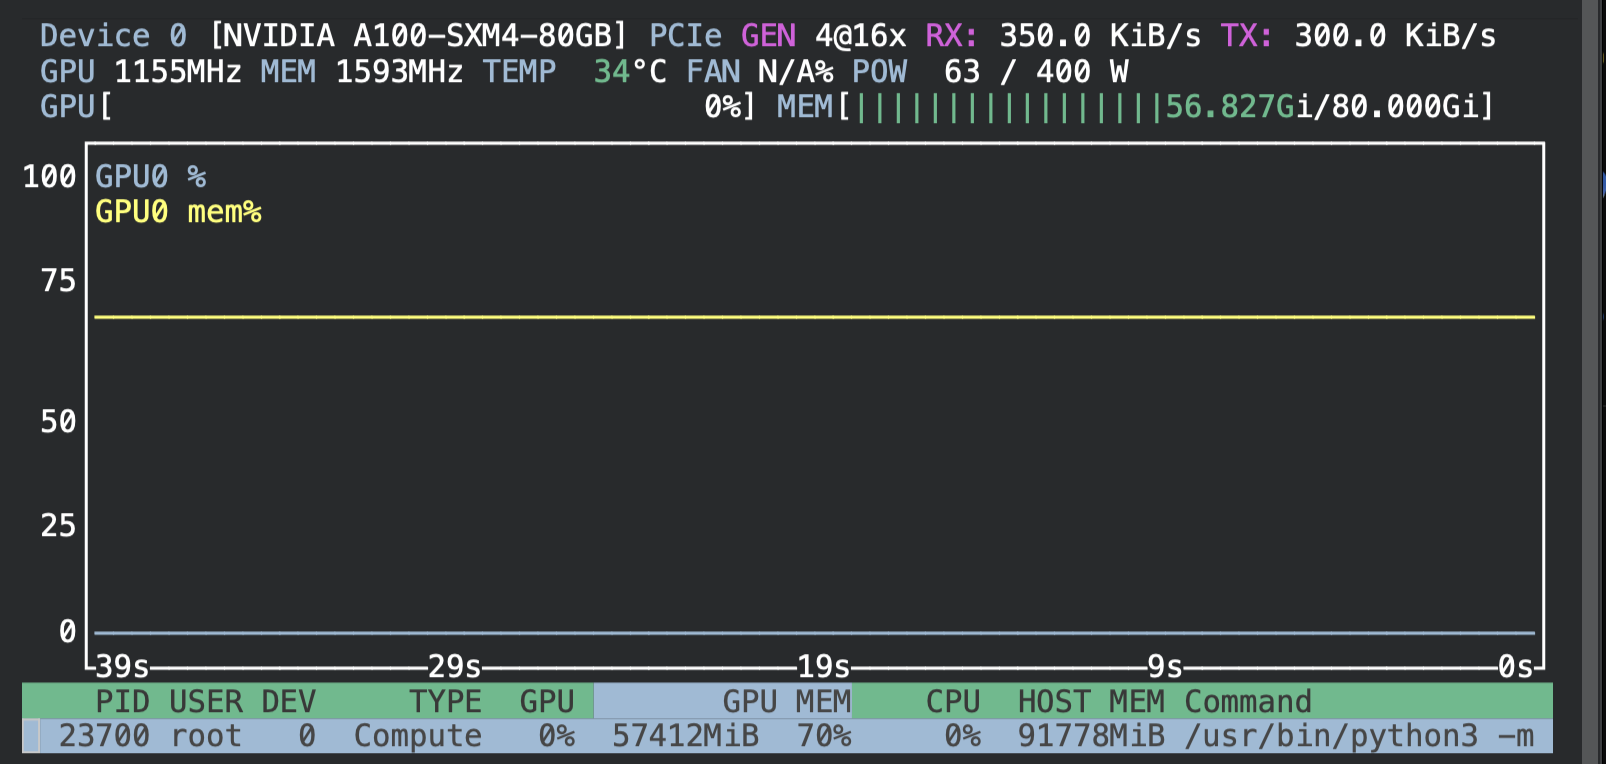